# Tugas 3: Ablasi dan Analisis Fitur (3c)

Notebook ini **hanya memuat hasil** yang sudah dihitung skrip di `src/` dan menampilkan tabel serta gambar.
Tidak ada pelatihan model di sini. Analisis 3c bersifat **deskriptif**: hasilnya tidak dipakai untuk mengubah
Model C, fitur, atau hyperparameter. Test (167 hari) kecil, jadi selisih kecil dibaca sebagai kecenderungan,
bukan bukti.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
ABL = ROOT / "data" / "processed" / "ablation"
A3C = ROOT / "data" / "processed" / "analysis_3c"
FIG = A3C / "figures"
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

def show(name, width=900):
    display(Image(filename=str(FIG / name), width=width))

## 1. Reproduksi ablasi

Jalankan dari root repository (urutan):

```bash
.venv/bin/python src/bert_text.py --compose title_body          # teks jalur BERT
.venv/bin/python src/extract_bert_embeddings.py --compose title_body   # FinBERT/RoBERTa/Qwen (~66 menit, MPS)
.venv/bin/python src/select_model_c.py                          # finalis + CV walk-forward
.venv/bin/python src/select_model_c_bert_path.py                # CV embedding lama vs jalur BERT
.venv/bin/python src/finalize_model_c.py                        # aturan final Model C (Keputusan 47)
.venv/bin/python src/ablation.py                                # ablasi, test dibuka sekali (~84 menit)
.venv/bin/python src/analysis_3c_headline_embed.py              # embedding judul FinBERT (3c.i)
.venv/bin/python src/analysis_3c.py                             # analisis 3c
.venv/bin/python src/analysis_3c_notebook.py                    # notebook ini
```

Protokol: split 772/165/167, `tune_xgb()` + `XGB_GRID` (akurasi valid), seed 42. C_optimized memakai grid
diperluas yang dipilih dengan CV di train+valid; perbandingan yang adil dengan A dan B memakai baris C.

In [2]:
matrix = pd.read_csv(ABL / "ablation_matrix.csv")
cols = ["row", "n_features", "val_accuracy", "test_accuracy", "test_correct_days", "test_accuracy_ci_low",
        "test_accuracy_ci_high", "test_macro_f1", "mcnemar_vs_naive_model_only", "mcnemar_vs_naive_naive_only",
        "mcnemar_vs_naive_p"]
matrix[cols].round(3)

,row,n_features,val_accuracy,test_accuracy,test_correct_days,test_accuracy_ci_low,test_accuracy_ci_high,test_macro_f1,mcnemar_vs_naive_model_only,mcnemar_vs_naive_naive_only,mcnemar_vs_naive_p
0,naive,1,0.727,0.713,119,0.629,0.766,0.715,0,0,1.000
1,A,10,0.806,0.731,122,0.641,0.790,0.737,20,17,0.743
2,B,33,0.812,0.766,128,0.694,0.820,0.772,23,14,0.188
3,C1,778,0.788,0.760,127,0.695,0.808,0.765,22,14,0.243
4,C2,982,0.800,0.754,126,0.683,0.808,0.760,22,15,0.324
5,C3,832,0.788,0.760,127,0.695,0.808,0.765,22,14,0.243
6,C,1036,0.800,0.772,129,0.695,0.832,0.777,24,14,0.143
7,C_optimized,1036,0.782,0.772,129,0.689,0.832,0.777,24,14,0.143
8,EF5_old,828,0.800,0.749,125,0.665,0.802,0.753,21,15,0.405


In [3]:
pair = pd.read_csv(ABL / "ablation_pairwise.csv")
pair[["comparison", "delta_accuracy_second_minus_first", "delta_accuracy_ci_low", "delta_accuracy_ci_high",
      "delta_macro_f1_second_minus_first", "delta_macro_f1_ci_low", "delta_macro_f1_ci_high",
      "mcnemar_second_only_correct", "mcnemar_first_only_correct", "mcnemar_p_value"]].round(3)

,comparison,delta_accuracy_second_minus_first,delta_accuracy_ci_low,delta_accuracy_ci_high,delta_macro_f1_second_minus_first,delta_macro_f1_ci_low,delta_macro_f1_ci_high,mcnemar_second_only_correct,mcnemar_first_only_correct,mcnemar_p_value
0,A vs B,0.036,-0.006,0.084,0.035,-0.011,0.078,9,3,0.146
1,B vs C,0.006,-0.042,0.054,0.004,-0.042,0.057,8,7,1.000
2,A vs C,0.042,-0.018,0.108,0.040,-0.020,0.106,14,7,0.189
3,EF5_old vs C,0.024,-0.006,0.066,0.024,-0.006,0.071,7,3,0.344


## 2. 3c.i: Ruang embedding judul (FinBERT), high vs low

Embedding FinBERT per judul (6.013 artikel, `clean_text()` saja), label = kelas volatilitas hari `target_date`.
PCA-50 di-fit di train, lalu t-SNE (perplexity 30, seed 42). Bentuk penanda: ● train, ■ valid, ▲ test.

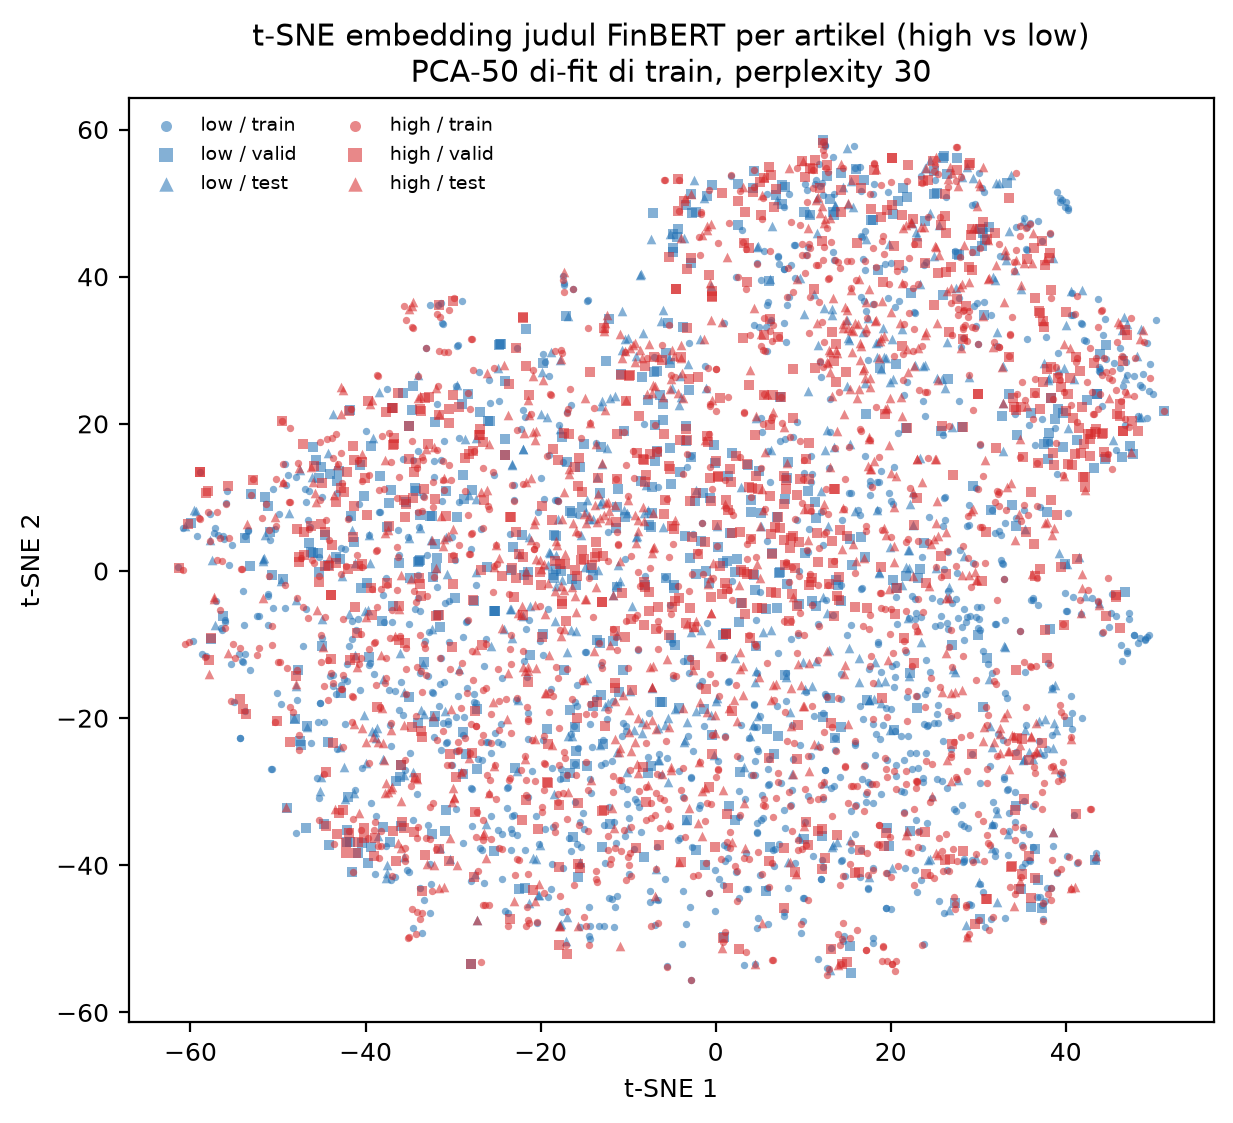

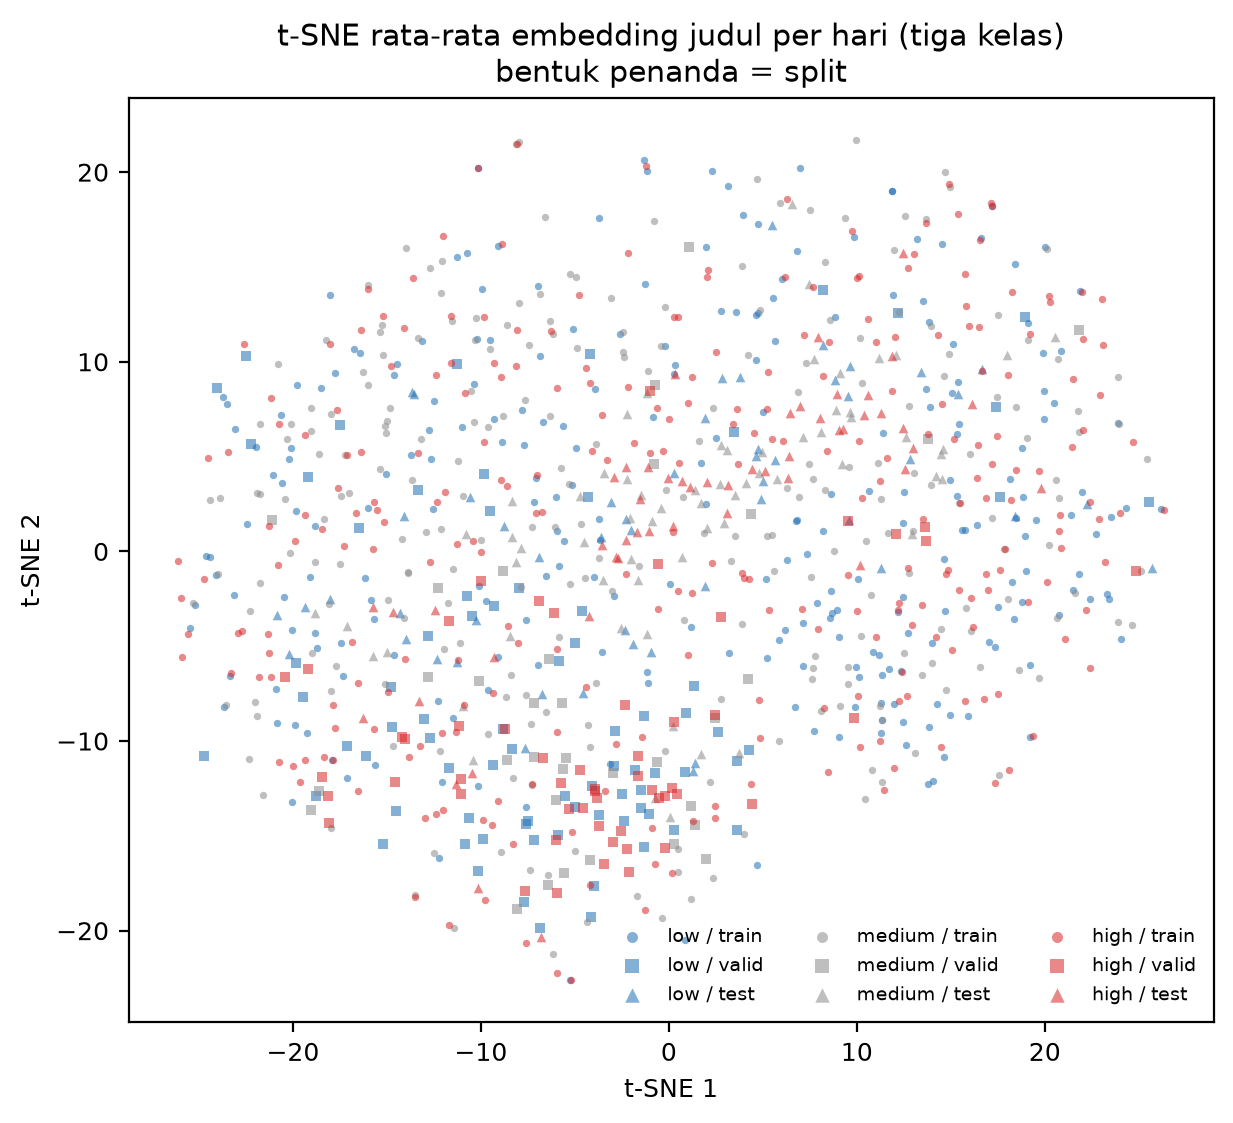

In [4]:
show("3ci_tsne_artikel_high_low.png", 650)
show("3ci_tsne_hari_3kelas.png", 650)

**Uji kuantitatif.** Silhouette dan kNN (k=15, CV kronologis 5 fold per tanggal) dibandingkan dengan dua baseline:
label hari diacak (100x) dan geser sirkular label hari (100x, pelengkap; mempertahankan autokorelasi rezim).
Pemisahan hanya disebut ada bila melampaui baseline acak.

In [5]:
sep = pd.read_csv(A3C / "separation_tests.csv")
keep = ["level", "n_rows", "silhouette", "silhouette_perm_mean", "silhouette_perm_p", "silhouette_circshift_mean",
        "silhouette_circshift_p", "knn_accuracy", "knn_accuracy_perm_mean", "knn_accuracy_perm_p",
        "knn_balanced_accuracy", "knn_balanced_accuracy_perm_mean", "knn_balanced_accuracy_perm_p",
        "knn_balanced_accuracy_circshift_p"]
sep[keep].T

,0,1
level,"artikel (high vs low, PCA-50)","hari (high vs low, PCA-50)"
n_rows,4195,759
silhouette,0.001316,0.001573
silhouette_perm_mean,0.00022,0.000025
silhouette_perm_p,0.009901,0.039604
silhouette_circshift_mean,0.001673,0.003599
silhouette_circshift_p,0.514851,0.90099
knn_accuracy,0.440924,0.439683
knn_accuracy_perm_mean,0.497717,0.498032
knn_accuracy_perm_p,1.0,0.990099


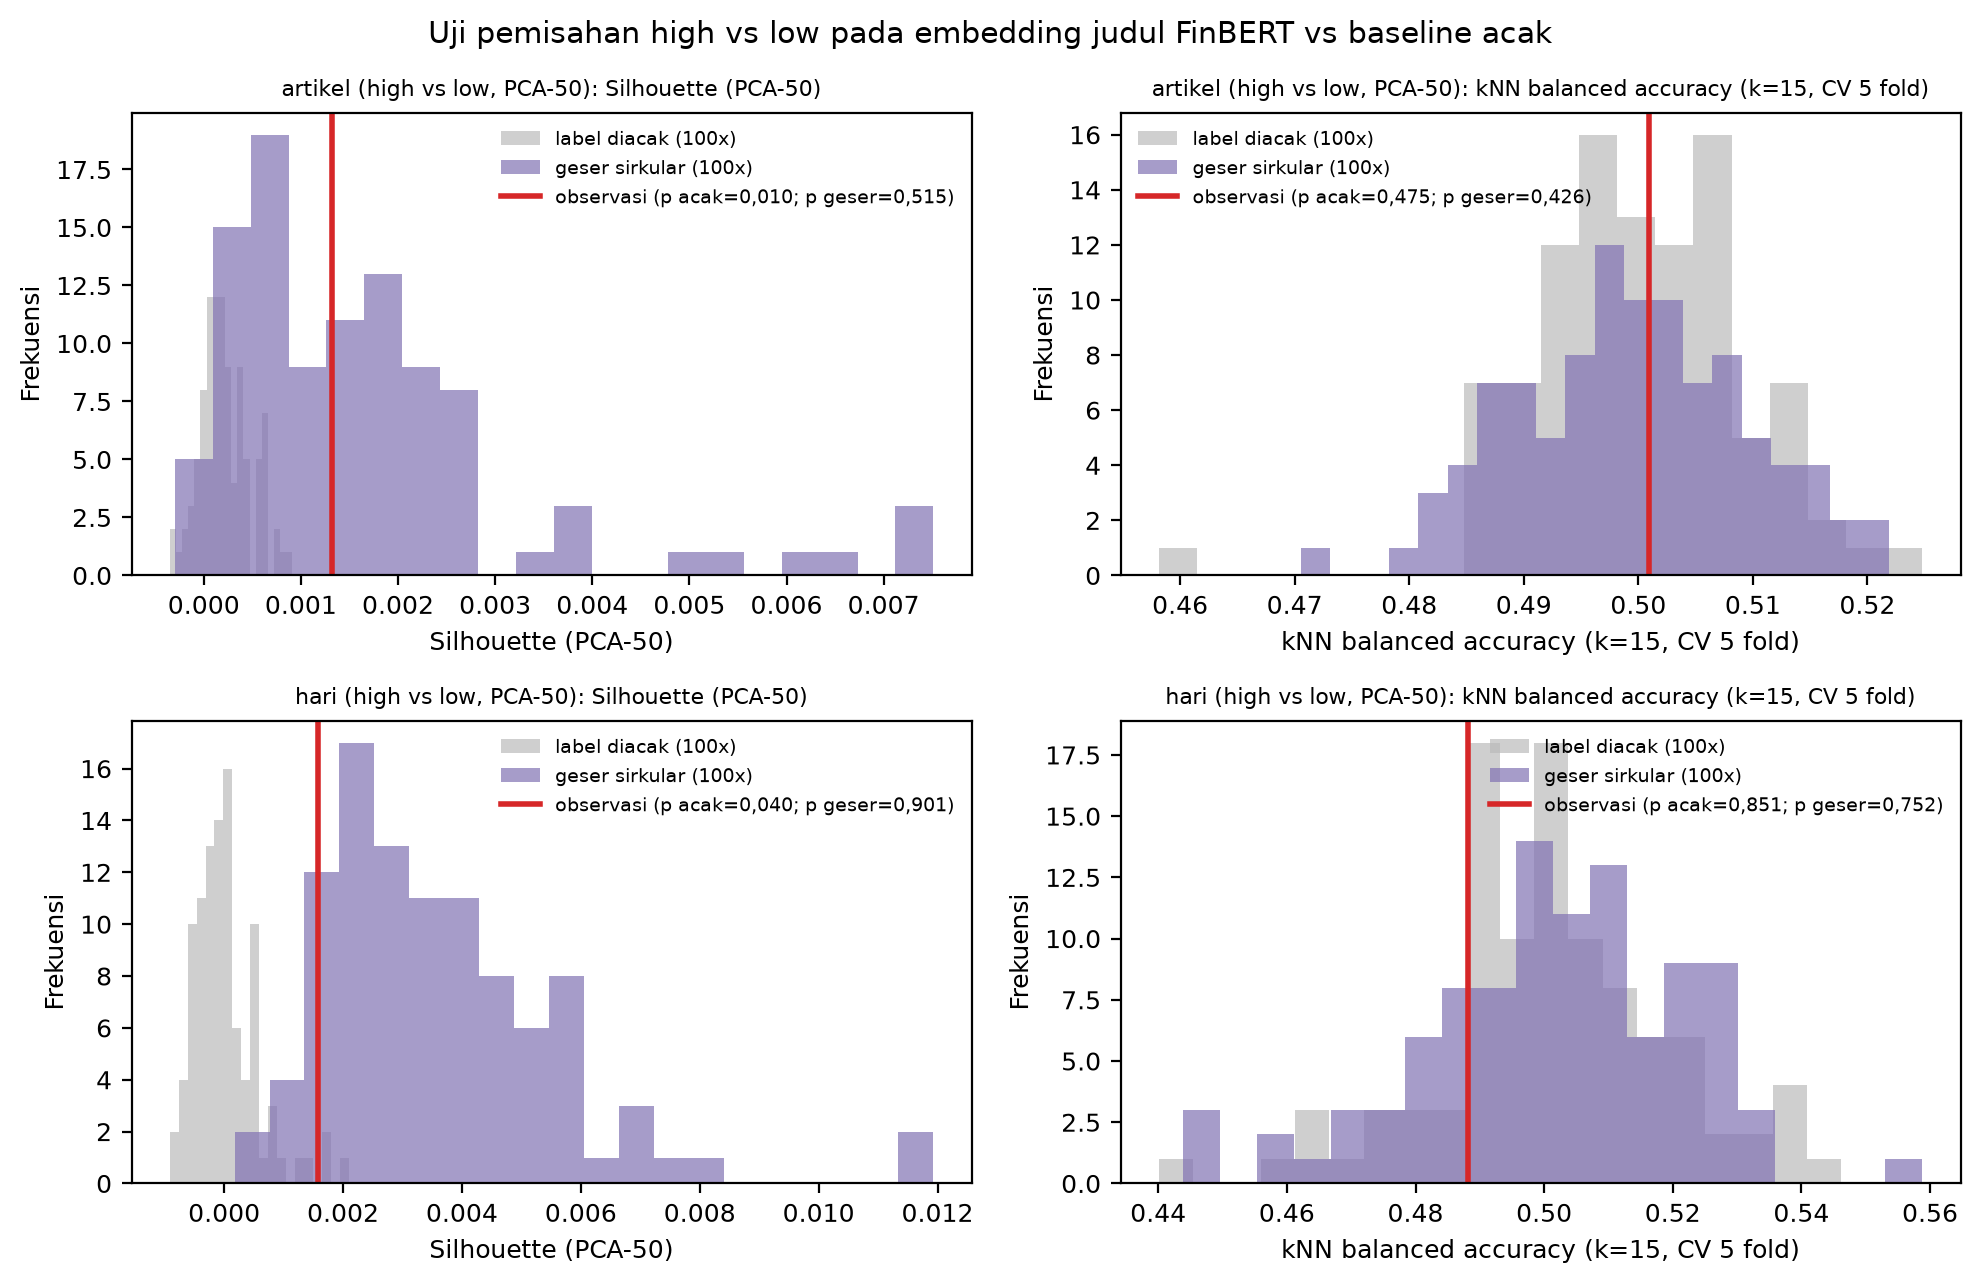

In [6]:
show("3ci_uji_pemisahan_null.png", 900)

In [7]:
near = pd.read_csv(A3C / "nearest_titles_to_centroid.csv")
near[["cluster", "rank", "target_date", "title", "cosine_to_centroid"]].round(3)

,cluster,rank,target_date,title,cosine_to_centroid
0,high,1,2024-05-16,"Georgia president holds talks on 'how to save' the country as U.S., EU and NATO decry 'Russian law'",0.884
1,high,2,2024-05-13,Ukraine war updates: Putin says Russia 'will not allow anyone to threaten us' as Moscow revels in military might,0.874
2,high,3,2024-11-20,Russia-U.S. tensions briefly hit global markets as Putin lowers the threshold for a nuclear strike,0.873
3,high,4,2024-04-16,Ukraine war updates: Kremlin warns escalation in Middle East is 'in no one's interests' but won't condemn ally Iran'...,0.866
4,high,5,2024-09-10,"Trump's vow of 100% tariffs on nations that snub the dollar is a lose-lose for China and U.S., economist says",0.864
5,high,6,2023-10-26,"U.S. likely to tighten sanctions on Iran crude oil amid Israel-Hamas war, RBC's Helima Croft says",0.862
6,high,7,2024-04-17,Ukraine war updates: China's Xi lays out 4 priorities to resolve Ukraine 'crisis'; Russia intensifies efforts to sei...,0.860
7,high,8,2024-04-16,"U.S. ready to sanction Chinese banks if they aid Russia's war machine, Yellen says",0.858
8,high,9,2024-05-20,Russia-Ukraine war live updates: Putin says capturing Ukraine's Kharkiv is not part of Russia's current plan; power ...,0.857
9,high,10,2022-05-09,Op-ed: Russia's war on Ukraine shows the urgent need to move away from fossil fuels as fast as possible,0.853


## 3. 3c.ii: Feature importance dan interpretabilitas

**Permutation importance per blok**: baris satu blok diacak utuh, 50 ulangan, seed 42. Validasi = utama,
test = pelengkap. Ukuran ini menggantikan importance gain per blok yang bias terhadap jumlah kolom (Keputusan 48).

In [8]:
pi = pd.read_csv(A3C / "permutation_importance_blocks.csv")
pi[["model", "split", "block", "n_columns", "base_macro_f1", "drop_macro_f1_mean", "drop_macro_f1_sd",
    "drop_accuracy_mean", "drop_accuracy_sd"]].round(4)

,model,split,block,n_columns,base_macro_f1,drop_macro_f1_mean,drop_macro_f1_sd,drop_accuracy_mean,drop_accuracy_sd
0,C,valid,price,10,0.7698,0.4500,0.0345,0.4510,0.0349
1,C,valid,finbert,768,0.7698,0.0071,0.0168,0.0057,0.0157
2,C,valid,top2vec,204,0.7698,0.0108,0.0069,0.0084,0.0071
3,C,valid,ner,54,0.7698,0.0012,0.0022,0.0015,0.0026
4,C,test,price,10,0.7766,0.4395,0.0338,0.4284,0.0328
5,C,test,finbert,768,0.7766,0.0198,0.0151,0.0213,0.0156
6,C,test,top2vec,204,0.7766,0.0031,0.0079,0.0032,0.0083
7,C,test,ner,54,0.7766,0.0004,0.0034,0.0005,0.0036
8,B,valid,price,10,0.7810,0.4642,0.0355,0.4613,0.0362
9,B,valid,lm,3,0.7810,0.0065,0.0099,0.0073,0.0099


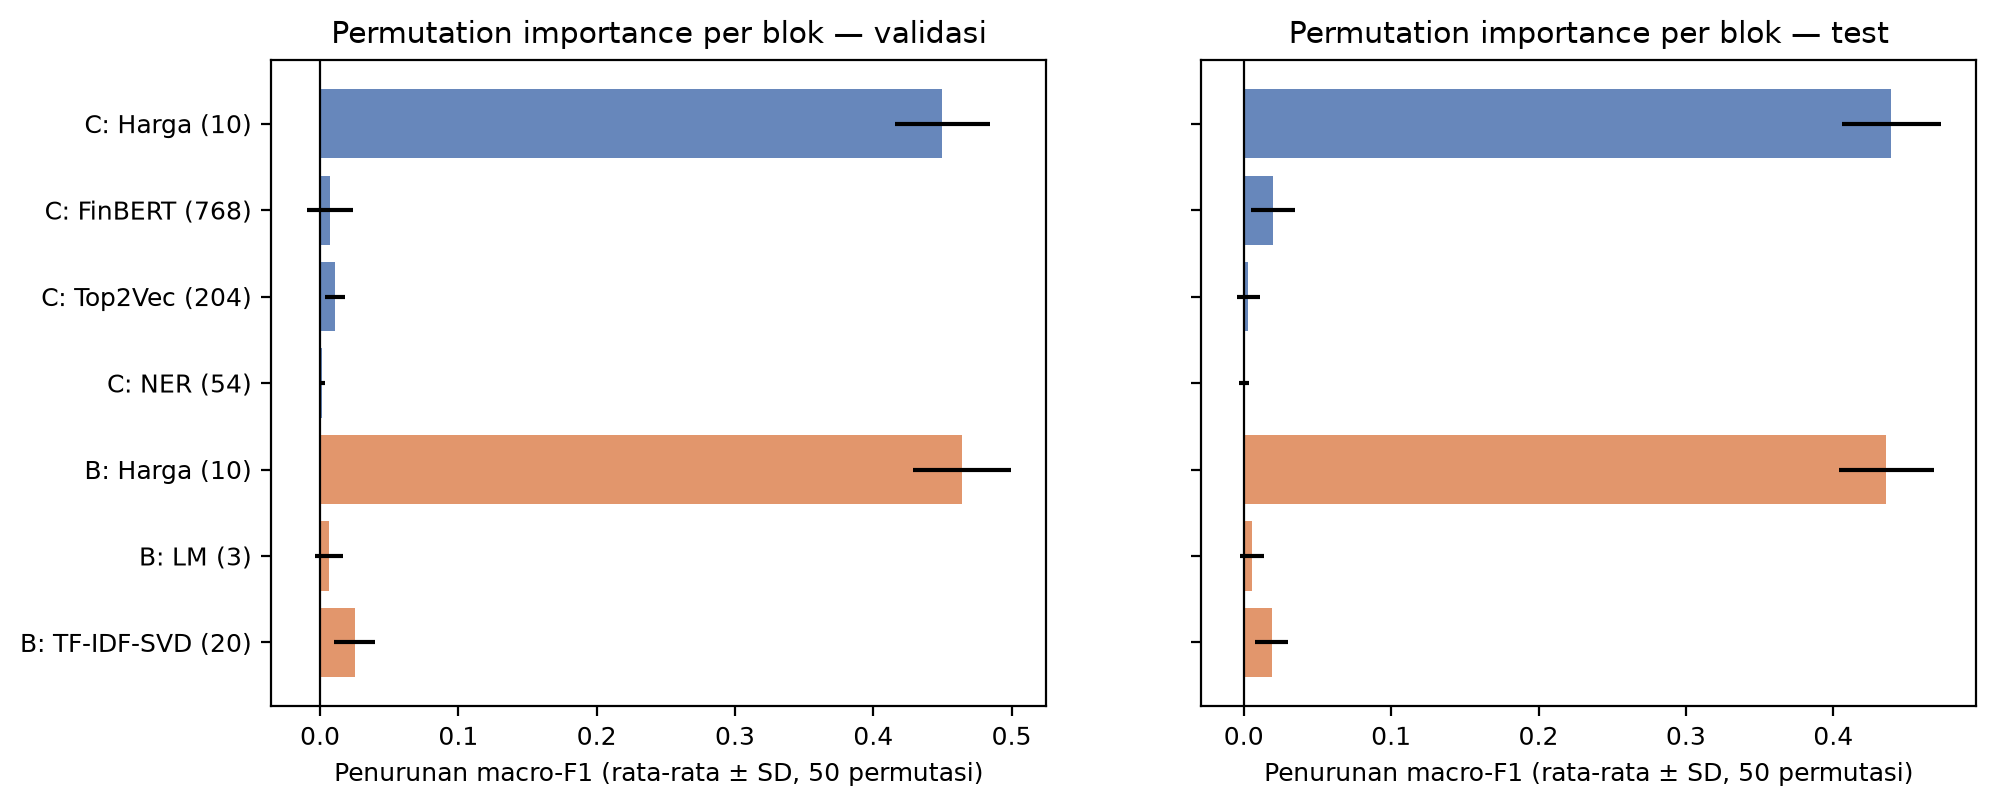

In [9]:
show("3cii_permutation_importance_blok.png", 900)

**SHAP bawaan XGBoost** (`pred_contribs=True`, satuan log-odds) di test, Model C: rata-rata Σ|SHAP| per hari,
per blok dan kelas. Dimensi FinBERT tidak ditafsirkan satu per satu.

In [10]:
shap_c = pd.read_csv(A3C / "shap_blocks_per_class_C_test.csv")
shap_c.pivot(index="block", columns="class", values="mean_abs_shap_sum").round(3)

class,high,low,medium
block,,,
finbert,0.902,0.747,0.937
ner,0.085,0.012,0.009
price,1.601,1.955,1.075
top2vec,0.133,0.076,0.048


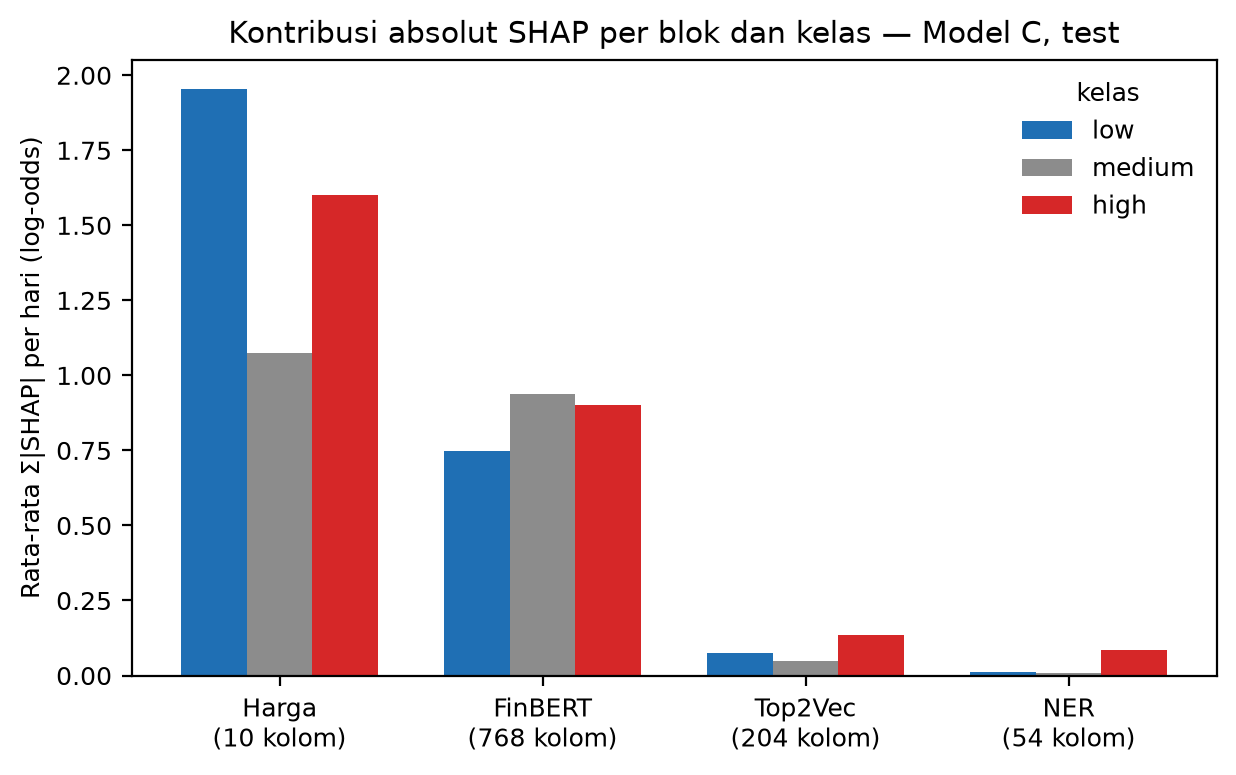

In [11]:
show("3cii_shap_blok_per_kelas.png", 650)

In [12]:
top = pd.read_csv(A3C / "top2vec_top10_shap.csv")
top[["rank", "feature", "feature_kind", "topic_words", "mean_abs_shap_all_classes"]].round(4)

,rank,feature,feature_kind,topic_words,mean_abs_shap_all_classes
0,1,topic_topic_14_count,count,"treasury yields, treasury yield, federal reserve, yields spiked, yields prices, monetary easing",0.1058
1,2,topic_topic_21_mean,mean,"chinese manufacturers, chinese firms, chinese automakers, semiconductor industry, chip shortage, semiconductor firms",0.0252
2,3,topic_dominant_topic_share,agregat,NaN,0.0211
3,4,topic_topic_41_mean,mean,"russian oligarchs, russia onslaught, russian oligarch, banning russian, enabler russia, bypassing ukraine",0.0200
4,5,topic_topic_38_mean,mean,"nato secretary, nato newest, lambasting nato, nato ally, nato alliance, member nato",0.0170
5,6,topic_topic_34_mean,mean,"defense contractors, aerospace defense, defense stocks, military buildup, defense spending, technology stocks",0.0138
6,7,topic_topic_22_mean,mean,"european stocks, russian banks, kyiv deposits, russian oligarchs, russian oligarch, ukrainian advances",0.0113
7,8,topic_topic_entropy,agregat,NaN,0.0085
8,9,topic_topic_62_mean,mean,"treasury yields, treasury yield, monetary easing, russian banks, sell treasurys, treasury bonds",0.0077
9,10,topic_topic_08_count,count,"specific tariffs, hefty tariffs, tariff hikes, impose tariffs, sweeping tariffs, tariff threats",0.0054


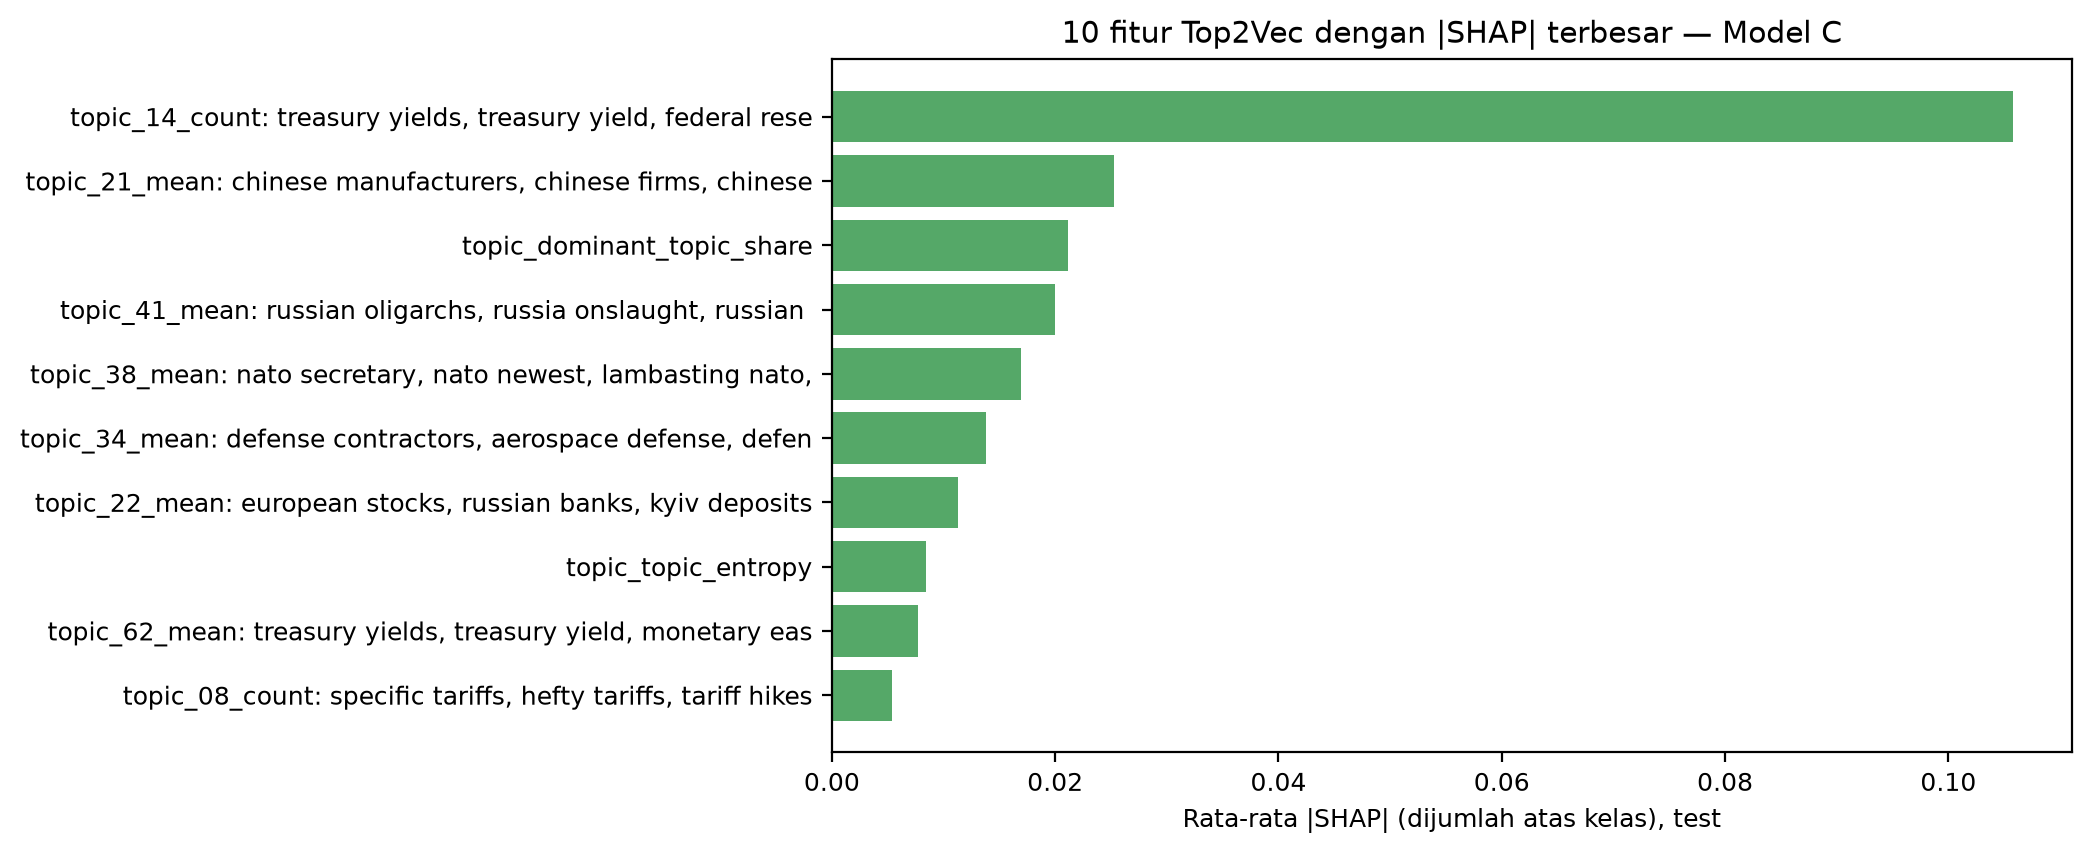

In [13]:
show("3cii_top2vec_top10.png", 750)

**Model B: komponen TF-IDF-SVD** dengan |SHAP| test terbesar dan kata/bigram berbobot terbesar
(`svd.components_` × vocabulary TF-IDF yang di-fit di train).

In [14]:
terms = pd.read_csv(A3C / "model_b_svd_top_terms.csv")
(terms.groupby(["rank_component", "component", "sign"])["term"].apply(lambda s: ", ".join(s))
      .unstack("sign")[["positif", "negatif"]])

,sign,positif,negatif
rank_component,component,,
1,tfidf_svd_5,"gas, energy, climate, cramer, europe, natural gas, nord, nord stream, gazprom, oil gas, fossil, pipeline, natural, s...","ukraine, opec, barrels, nato, trump, barrels per, per, per day, crude, million barrels, ukrainian, zelenskyy, barrel..."
2,tfidf_svd_14,"biden, oil, house, trump, cap, india, russian oil, administration, white house, white, taiwan, price cap, sanctions,...","china, russia, nuclear, tariffs, opec, per day, ai, barrels per, bakhmut, quarter, forces, war, saudi, growth, germany"
3,tfidf_svd_13,"cramer, gas, opec, germany, nord, nord stream, europe, taiwan, ukraine, stream, trump, biden, pipeline, jim cramer, ...","india, climate, shell, bp, billion, russian, quarter, cap, sanctions, profit, company, russian oil, turkey, earnings..."
4,tfidf_svd_9,"nato, red sea, sweden, iran, taiwan, finland, red, houthi, turkey, sea, shipping, vessels, attack, houthis, erdogan","korea, north korea, north, korean, india, opec, south, gaza, climate, prigozhin, hamas, south korea, north korean, w..."
5,tfidf_svd_8,"iran, iranian, saudi, nuclear, tehran, trump, deal, raisi, arabia, saudi arabia, climate, india, gas, islamic, nucle...","korea, korean, cramer, nato, north, north korea, gaza, sweden, south, finland, hamas, south korea, index, south kore..."


In [15]:
meta = json.loads((A3C / "metadata.json").read_text())
display(Markdown("**NER di Model C (SHAP test):** " + json.dumps(meta["part_ii"]["ner"])))
pi[(pi["model"] == "C") & (pi["block"] == "ner")][["split", "drop_macro_f1_mean", "drop_macro_f1_sd"]].round(4)

**NER di Model C (SHAP test):** {"mean_abs_shap_block_total": 0.1057320386171341, "max_feature_mean_abs_shap": 0.040272850543260574, "n_ner_features_with_nonzero_shap": 8, "n_splits_on_ner_features": 38}

,split,drop_macro_f1_mean,drop_macro_f1_sd
3,valid,0.0012,0.0022
7,test,0.0004,0.0034


**Peristiwa spesifik**: 10 hari test dengan kontribusi SHAP blok teks (FinBERT + Top2Vec + NER) terbesar
terhadap kelas yang diprediksi C. Judul = 3 artikel dengan `relevance_score` tertinggi.

In [16]:
ev = pd.read_csv(A3C / "events_top10_text_contribution.csv")
ev[["date", "true", "pred_A", "pred_C", "n_news", "text_shap_to_pred_class", "price_shap_to_pred_class",
    "dominant_topic", "dominant_topic_words", "titles_top3"]].round(3)

,date,true,pred_A,pred_C,n_news,text_shap_to_pred_class,price_shap_to_pred_class,dominant_topic,dominant_topic_words,titles_top3
0,2026-06-17,high,high,high,23,0.474,2.511,0,"blockades iranian, blockade iranian, iranian attacks, iranian ports, iranian targets, attacked iran",Brent falls below $80 per barrel on report U.S. will allow Iran to sell oil immediately | Trump turns his attention ...
1,2026-01-02,low,low,low,3,0.441,0.912,5,"specific tariffs, tariff hikes, hefty tariffs, sectoral tariffs, stacking tariffs, tariff announcements",Op-ed: China won the 2025 battle in Trump's trade war. Here's what comes next | Champagne sales surge at New Year - ...
2,2026-06-12,high,high,high,12,0.420,2.544,0,"blockades iranian, blockade iranian, iranian attacks, iranian ports, iranian targets, attacked iran",Investors brace for a 'long grind' as Iran war escalation dims hopes of an early end to hostilities | Trump threaten...
3,2026-04-29,high,high,high,8,0.416,2.633,4,"iranian attacks, blockades iranian, tehran bipartisan, blockade iranian, attacked iran, iran proxies",UAE's shock OPEC exit: What it means for the oil cartel's future and for crude prices | U.S. oil hovers near $100 on...
4,2026-07-22,medium,high,high,8,0.413,0.742,0,"blockades iranian, blockade iranian, iranian attacks, iranian ports, iranian targets, attacked iran",U.S. strikes Iran and Houthis threaten Saudi Arabia shipping as mediators push 10-day ceasefire | CNBC Daily Open: T...
5,2026-05-13,high,high,high,7,0.407,1.152,4,"iranian attacks, blockades iranian, tehran bipartisan, blockade iranian, attacked iran, iran proxies","CNBC Daily Open: Iran ceasefire on life support, but market volatility is alive and kicking | Asia markets mixed as ..."
6,2026-04-14,high,high,high,18,0.397,2.499,4,"iranian attacks, blockades iranian, tehran bipartisan, blockade iranian, attacked iran, iran proxies",European markets close lower as U.S. blockade of Strait of Hormuz begins | Trump threatens 50% tariffs on China as r...
7,2026-03-12,high,high,high,19,0.385,2.634,4,"iranian attacks, blockades iranian, tehran bipartisan, blockade iranian, attacked iran, iran proxies",CNBC Daily Open: Oil and trade tariff uncertainty rattle global markets | Jim Cramer says these 3 stock market theme...
8,2026-03-26,medium,high,high,16,0.372,0.647,4,"iranian attacks, blockades iranian, tehran bipartisan, blockade iranian, attacked iran, iran proxies",Iran has no intention to hold talks with U.S; foreign minister says Trump proposal to end war being reviewed | Treas...
9,2026-03-27,high,medium,medium,20,0.366,0.993,0,"blockades iranian, blockade iranian, iranian attacks, iranian ports, iranian targets, attacked iran","CNBC Daily Open: Iran rejects ceasefire, but reviews peace plan | The oil market is in 'backwardation' - Here's what..."


## 4. 3c.iii: Analisis korelasi dan error

Kategori per hari test (A = harga saja). *NLP membantu* = A salah, model NLP benar; *NLP menambah noise* = A benar,
model NLP salah. Jumlahnya di-assert sama dengan McNemar di `ablation_pairwise.csv`.

In [17]:
pd.read_csv(A3C / "error_categories_counts.csv")

,kategori,A_vs_C,A_vs_B
0,keduanya benar,115,119
1,keduanya salah,31,36
2,NLP membantu,14,9
3,NLP menambah noise,7,3


**Sinyal palsu pasar**: hari ketika naive (kelas kemarin) salah, atau A salah dengan arah perubahan kelas
yang salah. Berapa yang dikoreksi oleh B dan C?

In [18]:
pd.read_csv(A3C / "false_market_signal_summary.csv").T

,0
n_test_days,167
n_naive_wrong,48
n_A_wrong_direction,39
n_flagged,65
n_flagged_both_conditions,22
flagged_corrected_by_A,20
naive_wrong_corrected_by_A,20
A_wrong_direction_corrected_by_A,0
flagged_corrected_by_B,26
naive_wrong_corrected_by_B,23


In [19]:
hn = pd.read_csv(A3C / "help_noise_days_A_vs_C.csv")
hn[["date", "cat_A_vs_C", "true", "pred_naive", "pred_A", "pred_B", "pred_C", "log_return", "realized_vol", "n_news",
    "dominant_topic_words", "text_abs_shap_C_pred_class", "titles_top3"]].round(4)

,date,cat_A_vs_C,true,pred_naive,pred_A,pred_B,pred_C,log_return,realized_vol,n_news,dominant_topic_words,text_abs_shap_C_pred_class,titles_top3
0,2026-01-05,NLP membantu,low,low,medium,medium,low,0.0014,0.0021,5,"venezuelan oil, operation venezuela, venezuelan crude, operating venezuela, venezuelan president, intervention venez...",1.2607,Defense stocks drive Asia markets to record highs after U.S. captures Venezuela's Maduro | Trump says U.S. will inte...
1,2026-01-06,NLP membantu,low,low,medium,medium,low,0.0008,0.0020,8,"venezuelan oil, operation venezuela, venezuelan crude, operating venezuela, venezuelan president, intervention venez...",1.2869,Why Russia is treading carefully after the ousting of Kremlin ally Maduro | Global defense stocks soar as U.S. strik...
2,2026-01-22,NLP membantu,medium,low,low,medium,medium,-0.0036,0.0028,12,"control greenland, regarding greenland, purchase greenland, buy greenland, annexing greenland, acquire greenland",1.0174,Tech stocks rally after Trump says a 'framework' Greenland deal has been reached with NATO | Gold breaks new record ...
3,2026-02-18,NLP membantu,medium,medium,low,medium,medium,0.0024,0.0022,9,"iranian attacks, blockades iranian, tehran bipartisan, blockade iranian, attacked iran, iran proxies",1.1489,"Iran partially closes Strait of Hormuz, a vital oil choke point, as Tehran holds talks with U.S. | Oil prices fall a..."
4,2026-02-27,NLP membantu,medium,low,low,medium,medium,0.0013,0.0023,6,"sweeping tariffs, specific tariffs, hefty tariffs, tariff hikes, imposing tariffs, impose tariffs",1.0557,"Hungary accuses Ukraine of 'oil blockade,' deploys soldiers to key energy facilities | Russia says Cuba situation is..."
5,2026-04-15,NLP membantu,low,high,medium,low,low,0.0004,0.0016,16,"iranian attacks, blockades iranian, tehran bipartisan, blockade iranian, attacked iran, iran proxies",1.2228,China calls U.S. blockade of the Strait of Hormuz 'dangerous and irresponsible' | Oil prices stable as possible Wash...
6,2026-05-04,NLP membantu,medium,high,high,medium,medium,-0.0006,0.0030,22,"iranian attacks, blockades iranian, tehran bipartisan, blockade iranian, attacked iran, iran proxies",0.9188,Oil prices jump after Iran attacks UAE as U.S. tries to open Strait of Hormuz | Japan puts 'too much burden' on U.S....
7,2026-05-05,NLP membantu,low,medium,medium,medium,low,0.0033,0.0020,8,"blockades iranian, blockade iranian, iranian attacks, iranian ports, iranian targets, attacked iran",0.9281,Iran attacks UAE; U.S. says it sank boats in Strait of Hormuz | U.S. military denies Iran's claim it struck American...
8,2026-05-06,NLP membantu,medium,low,low,medium,medium,-0.0011,0.0025,10,"blockades iranian, blockade iranian, iranian attacks, iranian ports, iranian targets, attacked iran",1.0703,Markets on edge as fresh U.S.-Iran attacks dent optimism over a peace deal | CNBC Daily Open: Trump's indefinite cea...
9,2026-06-02,NLP membantu,medium,medium,low,low,medium,-0.0011,0.0023,23,"iranian attacks, blockades iranian, tehran bipartisan, blockade iranian, attacked iran, iran proxies",0.8973,"Iran stops negotiations with U.S., vows to 'completely' block Strait of Hormuz: State media | Oil jumps more than 4%..."


**Pembanding antar-kategori** (deskriptif; Mann–Whitney membantu vs noise; n = 14 vs 7 sangat kecil).

In [20]:
display(pd.read_csv(A3C / "category_comparison_numeric.csv").round(3))
display(pd.read_csv(A3C / "category_by_true_class.csv"))
display(pd.read_csv(A3C / "category_by_month.csv"))

,variable,category,n,median,mean,U,p_value
0,n_news,NLP membantu,14,9.500,11.000,NaN,NaN
1,n_news,NLP menambah noise,7,8.000,9.143,NaN,NaN
2,n_news,keduanya benar,115,8.000,9.513,NaN,NaN
3,n_news,keduanya salah,31,10.000,12.806,NaN,NaN
4,n_news,Mann-Whitney membantu vs noise,21,NaN,NaN,60.5,0.443
5,text_abs_shap_C_pred_class,NLP membantu,14,1.037,1.055,NaN,NaN
6,text_abs_shap_C_pred_class,NLP menambah noise,7,1.078,1.136,NaN,NaN
7,text_abs_shap_C_pred_class,keduanya benar,115,1.018,0.987,NaN,NaN
8,text_abs_shap_C_pred_class,keduanya salah,31,0.994,1.022,NaN,NaN
9,text_abs_shap_C_pred_class,Mann-Whitney membantu vs noise,21,NaN,NaN,36.0,0.360


,cat_A_vs_C,low,medium,high
0,NLP membantu,5,8,1
1,NLP menambah noise,2,3,2
2,keduanya benar,40,39,36
3,keduanya salah,4,15,12


,cat_A_vs_C,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
0,NLP membantu,0,3,2,0,1,3,1,2,2,0
1,NLP menambah noise,0,1,3,1,0,0,2,0,0,0
2,keduanya benar,13,15,7,11,17,10,15,14,12,1
3,keduanya salah,0,1,5,5,3,3,2,7,5,0


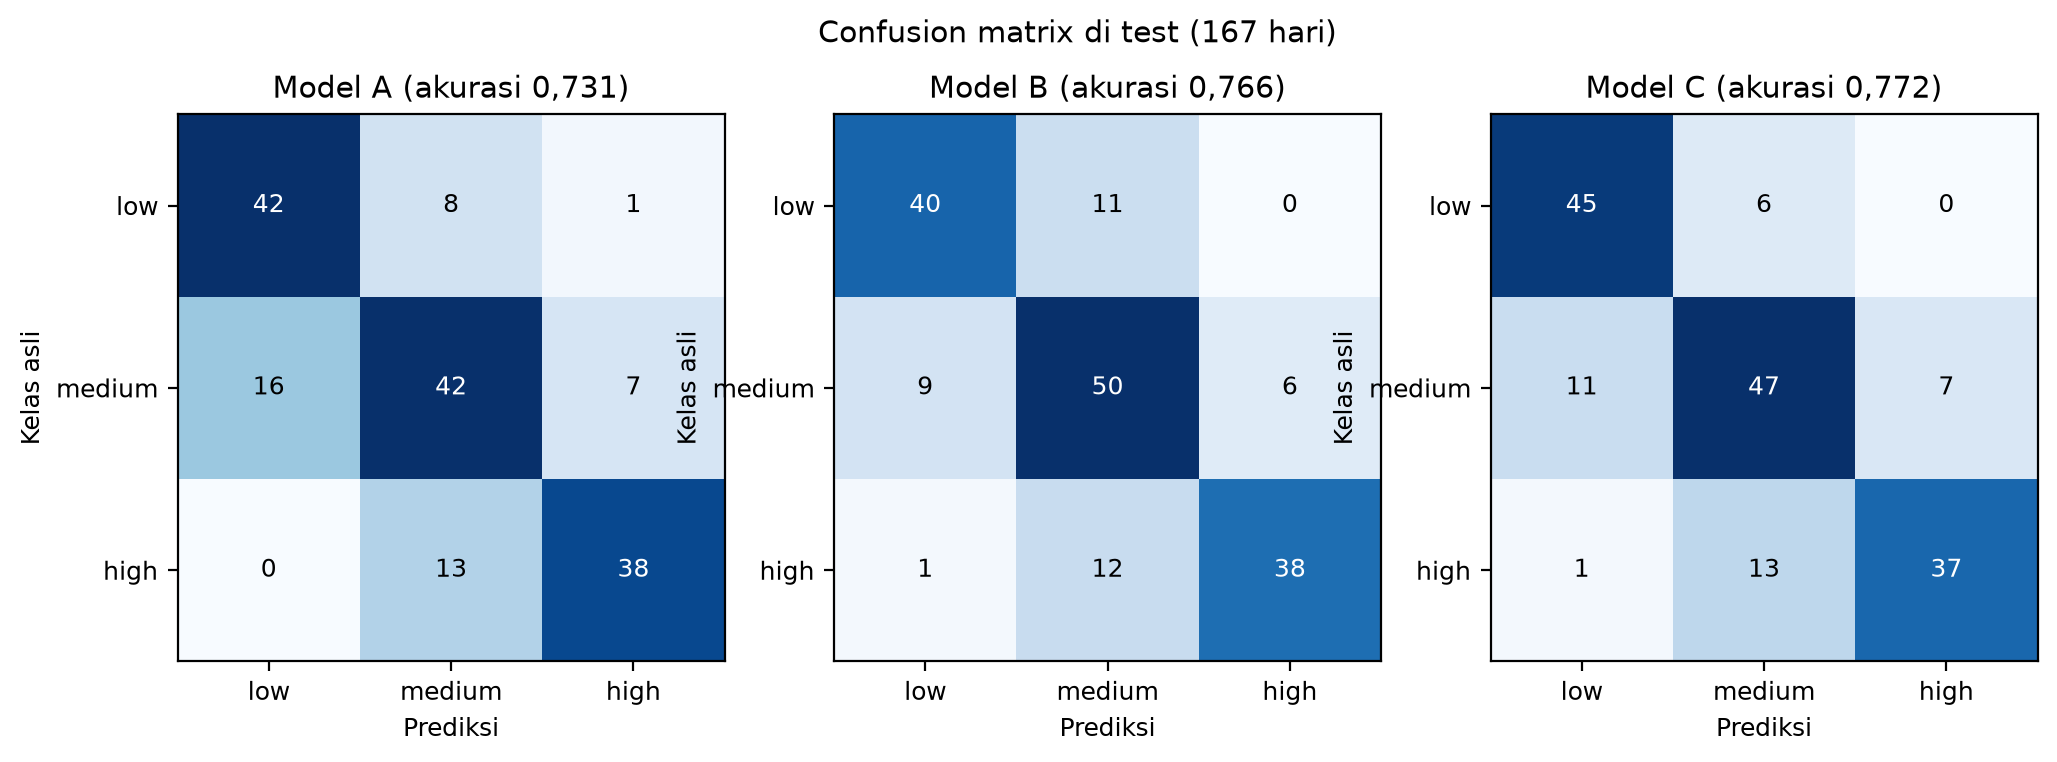

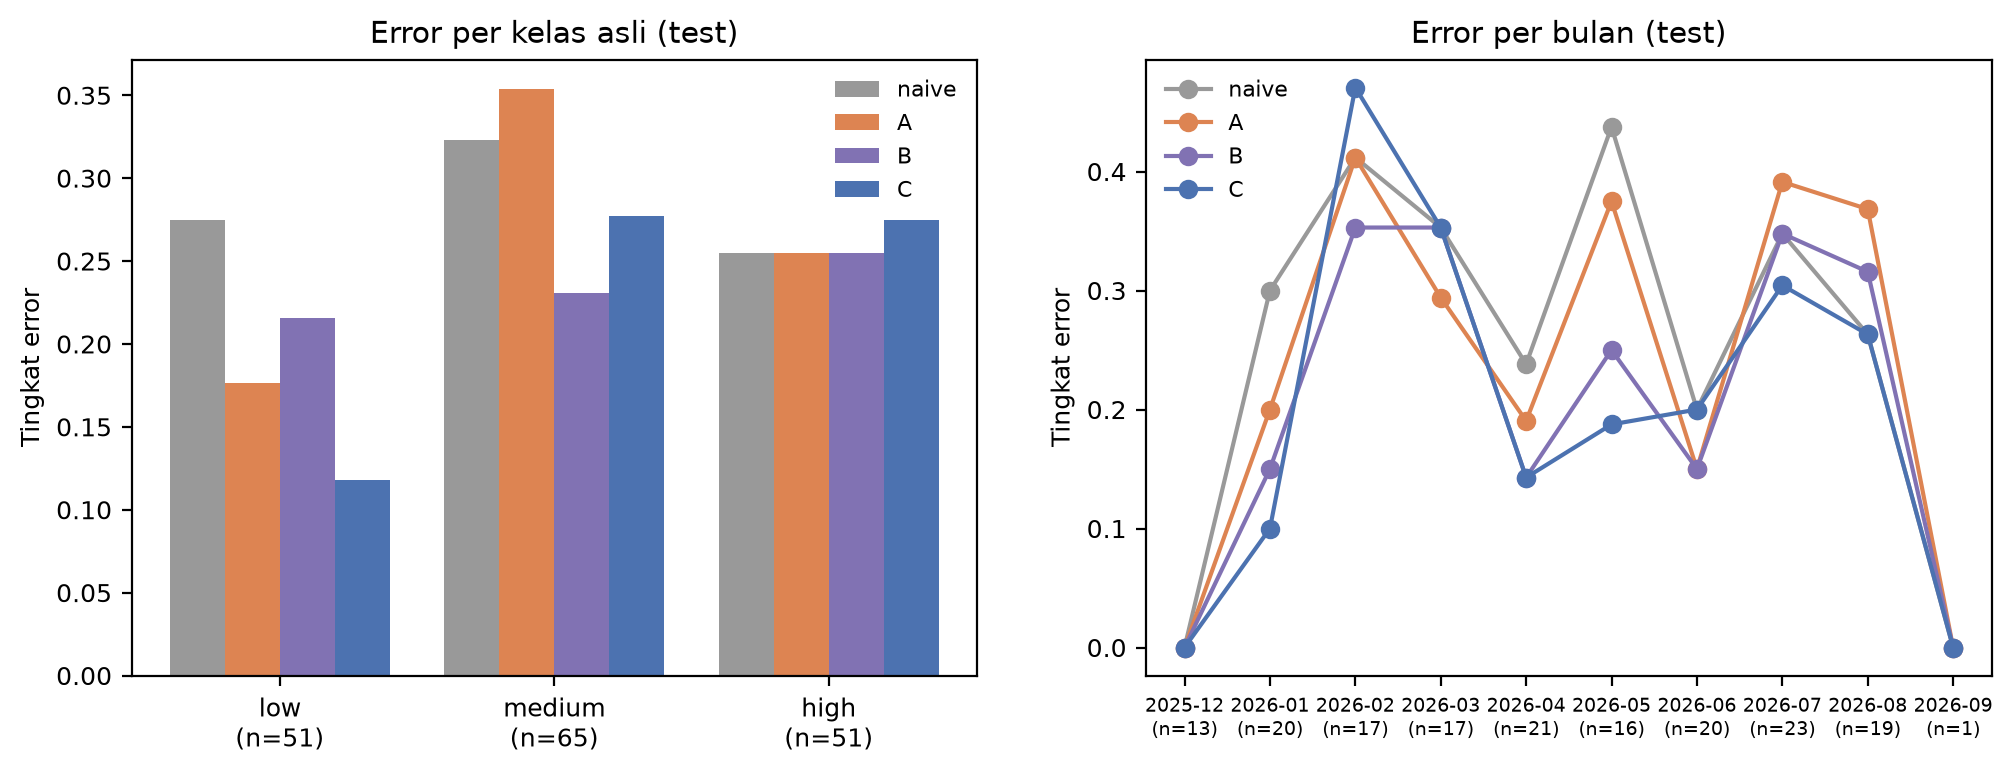

In [21]:
show("3ciii_confusion_ABC.png", 900)
show("3ciii_error_kelas_bulan.png", 900)

**Korelasi deskriptif di train** (Spearman vs `realized_vol`, koreksi Benjamini–Hochberg).

In [22]:
pd.read_csv(A3C / "spearman_train_text_vs_realized_vol.csv").round(4)

,variable,n,spearman_rho,p_value,p_bh,significant_bh_0_05
0,n_news,772,0.0325,0.3673,0.3673,False
1,mean_lm_polarity,772,0.0388,0.2813,0.3673,False
2,dominant_topic_share,772,-0.0443,0.2194,0.3673,False


## 5. Lingkungan

In [23]:
pd.Series(meta["versions"], name="versi").to_frame()

,versi
python,3.14.10
numpy,2.5.5
pandas,3.1.1
scikit-learn,1.9.1
scipy,1.18.1
xgboost,3.4.1
torch,2.15.0
transformers,5.24.0
matplotlib,3.11.2
nbformat,5.11.1
